In [1]:
import sys

print(sys.version)
print(sys.executable)


3.11.16 (main, Aug 12 2026, 23:03:19) [Clang 17.0.0 (clang-1700.6.4.2)]
/Users/debarghamishra/Downloads/Agentic_process_Intelligence/.venv/bin/python


In [2]:
import sqlite3
import pandas as pd
import pm4py
from pathlib import Path

DB_PATH = Path("../data/lrms_02_p2p.sqlite")

print("Database exists:", DB_PATH.exists())
print("Database path:", DB_PATH.resolve())



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Database exists: True
Database path: /Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/lrms_02_p2p.sqlite


In [3]:
conn = sqlite3.connect(DB_PATH)

print("Database connected successfully!")

Database connected successfully!


In [4]:
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

tables = pd.read_sql_query(query, conn)

tables

,name
0,event
1,event_ApprovePo
2,event_ApprovePr
3,event_CreatePo
4,event_CreatePobatch
5,event_CreatePr
6,event_MakePayment
7,event_ReceiveGoods
8,event_ReceiveInvoice
9,event_RejectPr


In [5]:
events = pd.read_sql_query(
    "SELECT * FROM event",
    conn
)

print("Number of events:", len(events))
print("Columns:", events.columns.tolist())

events.head()

Number of events: 8300
Columns: ['ocel_id', 'ocel_type']


,ocel_id,ocel_type
0,E264,Create PR
1,E531,Create PR
2,E2244,Create PR
3,E2280,Create PR
4,E2504,Create PR


In [6]:
ocel = pm4py.read_ocel2(str(DB_PATH))

print(type(ocel))

<class 'pm4py.objects.ocel.obj.OCEL'>


In [7]:
object_types = pm4py.ocel_get_object_types(ocel)

print("Object types:")

for obj_type in object_types:
    print("-", obj_type)

Object types:
- Goods Receipt
- Invoice
- Payment
- Purchase Order
- Purchase Requisition
- Supplier


In [8]:
print("Events:")
display(ocel.events.head())

Events:


,user,cost_center,ocel:eid,ocel:activity,ocel:timestamp,location
0,User17,CC11,E264,Create PR,2024-09-02 08:04:53+00:00,NaN
1,User42,CC15,E531,Create PR,2024-09-02 08:04:53+00:00,NaN
2,User31,CC9,E2244,Create PR,2024-09-02 08:04:54+00:00,NaN
3,User43,CC16,E2280,Create PR,2024-09-02 08:04:54+00:00,NaN
4,User17,CC6,E2504,Create PR,2024-09-02 08:04:54+00:00,NaN


In [9]:
print("Objects:")
display(ocel.objects.head())

Objects:


,condition,ocel:oid,amount,invoice_number,payment_method,total_amount,status,department,priority,supplier_name,supplier_rating,terms,ocel:type
0,Good,GRN4125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Goods Receipt
1,Good,GRN7903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Goods Receipt
2,Good,GRN1832,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Goods Receipt
3,Good,GRN9607,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Goods Receipt
4,Damaged,GRN470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Goods Receipt


In [10]:
print("Relations:")
display(ocel.relations.head())

Relations:


,ocel:eid,ocel:oid,ocel:qualifier,ocel:activity,ocel:timestamp,ocel:type
0,E264,PR31,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition
1,E531,PR63,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition
2,E2244,PR272,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
3,E2280,PR276,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
4,E2504,PR304,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition


In [11]:
activities = ocel.events["ocel:activity"].unique()

print("Activities:")

for activity in activities:
    print("-", activity)

Activities:
- Create PR
- Reject PR
- Approve PR
- Create PO (Batch)
- Create PO
- Approve PO
- Send PO to Supplier
- Receive Goods
- Receive Invoice
- Three-way Match - Successful
- Three-way Match - Mismatch Found
- Make Payment


In [12]:
print("EVENT COLUMNS")
print(ocel.events.columns.tolist())

print("\nRELATION COLUMNS")
print(ocel.relations.columns.tolist())

print("\nOBJECT COLUMNS")
print(ocel.objects.columns.tolist())

EVENT COLUMNS
['user', 'cost_center', 'ocel:eid', 'ocel:activity', 'ocel:timestamp', 'location']

RELATION COLUMNS
['ocel:eid', 'ocel:oid', 'ocel:qualifier', 'ocel:activity', 'ocel:timestamp', 'ocel:type']

OBJECT COLUMNS
['condition', 'ocel:oid', 'amount', 'invoice_number', 'payment_method', 'total_amount', 'status', 'department', 'priority', 'supplier_name', 'supplier_rating', 'terms', 'ocel:type']


In [13]:
events_df = ocel.events.copy()
relations_df = ocel.relations.copy()
objects_df = ocel.objects.copy()

print("Events:", events_df.shape)
print("Relations:", relations_df.shape)
print("Objects:", objects_df.shape)

Events: (8300, 6)
Relations: (16827, 6)
Objects: (4493, 13)


In [14]:
activity_counts = (
    events_df["ocel:activity"]
    .value_counts()
    .reset_index()
)

activity_counts.columns = ["activity", "event_count"]

activity_counts

,activity,event_count
0,Create PR,1000
1,Approve PR,900
2,Approve PO,900
3,Send PO to Supplier,900
4,Receive Goods,900
5,Receive Invoice,900
6,Make Payment,900
7,Three-way Match - Successful,823
8,Create PO (Batch),457
9,Create PO,443


In [15]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


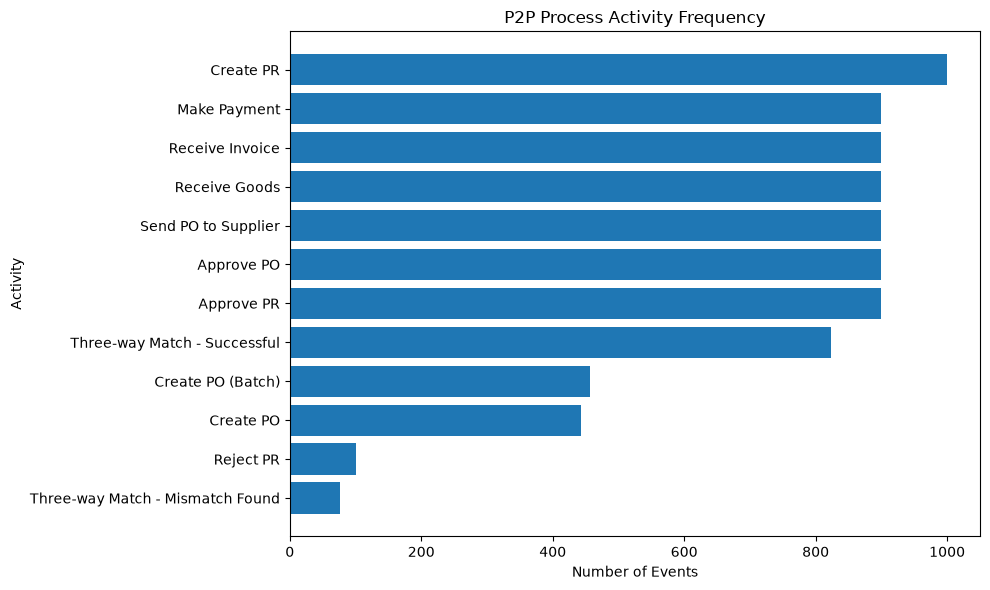

In [16]:
import matplotlib.pyplot as plt

activity_counts = activity_counts.sort_values(
    "event_count",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    activity_counts["activity"],
    activity_counts["event_count"]
)

plt.xlabel("Number of Events")
plt.ylabel("Activity")
plt.title("P2P Process Activity Frequency")

plt.tight_layout()
plt.show()

In [17]:
[m for m in activities if "Mismatch" in m]

['Three-way Match - Mismatch Found']

match_events = events_df[
    events_df["ocel:activity"].str.contains(
        "Three-way Match",
        case=False,
        na=False
    )
]

total_match_events = len(match_events)

mismatch_rate = (
    mismatch_count / total_match_events * 100
)

print(f"Three-way match events: {total_match_events}")
print(f"Mismatch events: {mismatch_count}")
print(f"Mismatch rate: {mismatch_rate:.2f}%")

In [18]:
mismatch_activity = [
    m for m in activities
    if "Mismatch" in m
][0]

mismatch_count = (
    events_df["ocel:activity"] == mismatch_activity
).sum()

print("Mismatch activity:", mismatch_activity)
print("Mismatch events:", mismatch_count)

Mismatch activity: Three-way Match - Mismatch Found
Mismatch events: 77


In [19]:
[m for m in activities if "Reject" in m]

['Reject PR']

In [20]:
reject_activity = [
    m for m in activities
    if "Reject" in m
][0]

reject_count = (
    events_df["ocel:activity"] == reject_activity
).sum()

print("Rejected PR events:", reject_count)

Rejected PR events: 100


In [21]:
pr_events = events_df[
    events_df["ocel:activity"].str.contains(
        "PR",
        case=False,
        na=False
    )
]

create_pr_count = (
    events_df["ocel:activity"] == "Create PR"
).sum()

rejection_rate = reject_count / create_pr_count * 100

print(f"PRs created: {create_pr_count}")
print(f"PRs rejected: {reject_count}")
print(f"PR rejection rate: {rejection_rate:.2f}%")

PRs created: 1000
PRs rejected: 100
PR rejection rate: 10.00%


In [22]:
events_df["ocel:timestamp"] = pd.to_datetime(
    events_df["ocel:timestamp"]
)

print(events_df["ocel:timestamp"].min())
print(events_df["ocel:timestamp"].max())

2024-09-02 08:04:53+00:00
2024-09-20 12:36:57+00:00


In [23]:
events_df[
    ["ocel:activity", "ocel:timestamp"]
].sort_values("ocel:timestamp").head(20)

,ocel:activity,ocel:timestamp
0,Create PR,2024-09-02 08:04:53+00:00
1,Create PR,2024-09-02 08:04:53+00:00
2,Create PR,2024-09-02 08:04:54+00:00
3,Create PR,2024-09-02 08:04:54+00:00
4,Create PR,2024-09-02 08:04:54+00:00
5,Create PR,2024-09-02 08:04:54+00:00
6,Create PR,2024-09-02 08:04:54+00:00
7,Create PR,2024-09-02 08:04:55+00:00
8,Create PR,2024-09-02 08:04:55+00:00
9,Create PR,2024-09-02 08:04:56+00:00


In [24]:
relations_df.head()

,ocel:eid,ocel:oid,ocel:qualifier,ocel:activity,ocel:timestamp,ocel:type
0,E264,PR31,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition
1,E531,PR63,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition
2,E2244,PR272,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
3,E2280,PR276,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
4,E2504,PR304,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition


In [25]:
relations_df.head(10)

,ocel:eid,ocel:oid,ocel:qualifier,ocel:activity,ocel:timestamp,ocel:type
0,E264,PR31,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition
1,E531,PR63,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition
2,E2244,PR272,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
3,E2280,PR276,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
4,E2504,PR304,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
5,E2598,PR316,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
6,E2796,PR338,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition
7,E4127,PR496,None,Create PR,2024-09-02 08:04:55+00:00,Purchase Requisition
8,E4230,PR509,None,Create PR,2024-09-02 08:04:55+00:00,Purchase Requisition
9,E6297,PR762,None,Create PR,2024-09-02 08:04:56+00:00,Purchase Requisition


In [26]:
event_object_df = relations_df.merge(
    events_df,
    on="ocel:eid",
    how="left"
)

event_object_df.head()

,ocel:eid,ocel:oid,ocel:qualifier,ocel:activity_x,ocel:timestamp_x,ocel:type,user,cost_center,ocel:activity_y,ocel:timestamp_y,location
0,E264,PR31,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition,User17,CC11,Create PR,2024-09-02 08:04:53+00:00,NaN
1,E531,PR63,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition,User42,CC15,Create PR,2024-09-02 08:04:53+00:00,NaN
2,E2244,PR272,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User31,CC9,Create PR,2024-09-02 08:04:54+00:00,NaN
3,E2280,PR276,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User43,CC16,Create PR,2024-09-02 08:04:54+00:00,NaN
4,E2504,PR304,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User17,CC6,Create PR,2024-09-02 08:04:54+00:00,NaN


In [27]:
event_object_df.columns.tolist()

['ocel:eid',
 'ocel:oid',
 'ocel:qualifier',
 'ocel:activity_x',
 'ocel:timestamp_x',
 'ocel:type',
 'user',
 'cost_center',
 'ocel:activity_y',
 'ocel:timestamp_y',
 'location']

In [28]:
relations_df["ocel:type"].value_counts()

ocel:type
Purchase Order          5400
Purchase Requisition    4227
Invoice                 2700
Supplier                1800
Goods Receipt           1800
Payment                  900
Name: count, dtype: int64

In [29]:
# Make sure timestamps are datetime objects
events_df["ocel:timestamp"] = pd.to_datetime(events_df["ocel:timestamp"])
relations_df["ocel:timestamp"] = pd.to_datetime(relations_df["ocel:timestamp"])

print("Timestamp conversion complete")
print(events_df["ocel:timestamp"].min())
print(events_df["ocel:timestamp"].max())

Timestamp conversion complete
2024-09-02 08:04:53+00:00
2024-09-20 12:36:57+00:00


In [30]:
event_object_df = relations_df.merge(
    events_df[
        [
            "ocel:eid",
            "user",
            "cost_center",
            "location"
        ]
    ],
    on="ocel:eid",
    how="left"
)

print("Shape:", event_object_df.shape)

event_object_df.head()

Shape: (16827, 9)


,ocel:eid,ocel:oid,ocel:qualifier,ocel:activity,ocel:timestamp,ocel:type,user,cost_center,location
0,E264,PR31,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition,User17,CC11,NaN
1,E531,PR63,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition,User42,CC15,NaN
2,E2244,PR272,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User31,CC9,NaN
3,E2280,PR276,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User43,CC16,NaN
4,E2504,PR304,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User17,CC6,NaN


In [31]:
pr_events = event_object_df[
    event_object_df["ocel:type"] == "Purchase Requisition"
].copy()

print("Purchase Requisition event relationships:", len(pr_events))

pr_events.head(20)

Purchase Requisition event relationships: 4227


,ocel:eid,ocel:oid,ocel:qualifier,ocel:activity,ocel:timestamp,ocel:type,user,cost_center,location
0,E264,PR31,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition,User17,CC11,NaN
1,E531,PR63,None,Create PR,2024-09-02 08:04:53+00:00,Purchase Requisition,User42,CC15,NaN
2,E2244,PR272,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User31,CC9,NaN
3,E2280,PR276,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User43,CC16,NaN
4,E2504,PR304,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User17,CC6,NaN
5,E2598,PR316,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User34,CC20,NaN
6,E2796,PR338,None,Create PR,2024-09-02 08:04:54+00:00,Purchase Requisition,User18,CC19,NaN
7,E4127,PR496,None,Create PR,2024-09-02 08:04:55+00:00,Purchase Requisition,User35,CC18,NaN
8,E4230,PR509,None,Create PR,2024-09-02 08:04:55+00:00,Purchase Requisition,User16,CC3,NaN
9,E6297,PR762,None,Create PR,2024-09-02 08:04:56+00:00,Purchase Requisition,User19,CC3,NaN


In [32]:
sample_pr = pr_events["ocel:oid"].iloc[0]

print("Sample PR:", sample_pr)

pr_events[
    pr_events["ocel:oid"] == sample_pr
].sort_values("ocel:timestamp")[
    [
        "ocel:eid",
        "ocel:oid",
        "ocel:activity",
        "ocel:timestamp"
    ]
]

Sample PR: PR31


,ocel:eid,ocel:oid,ocel:activity,ocel:timestamp
0,E264,PR31,Create PR,2024-09-02 08:04:53+00:00
252,E265,PR31,Approve PR,2024-09-02 08:18:53+00:00
2051,E266,PR31,Create PO,2024-09-02 09:06:53+00:00
3055,E5764,PR31,Create PO (Batch),2024-09-02 09:24:56+00:00
4752,E6308,PR31,Create PO (Batch),2024-09-02 09:51:56+00:00


In [33]:
pr_create = (
    pr_events[pr_events["ocel:activity"] == "Create PR"]
    .groupby("ocel:oid")["ocel:timestamp"]
    .min()
    .rename("create_time")
)

pr_approve = (
    pr_events[pr_events["ocel:activity"] == "Approve PR"]
    .groupby("ocel:oid")["ocel:timestamp"]
    .min()
    .rename("approve_time")
)

pr_cycle = pd.concat(
    [pr_create, pr_approve],
    axis=1
).dropna()

pr_cycle["approval_time_hours"] = (
    pr_cycle["approve_time"] - pr_cycle["create_time"]
).dt.total_seconds() / 3600

pr_cycle.head()

,create_time,approve_time,approval_time_hours
ocel:oid,,,
PR1,2024-09-02 08:10:53+00:00,2024-09-02 08:53:53+00:00,0.716667
PR10,2024-09-02 08:41:53+00:00,2024-09-02 09:19:53+00:00,0.633333
PR100,2024-09-02 08:07:53+00:00,2024-09-02 08:50:53+00:00,0.716667
PR1000,2024-09-02 08:10:57+00:00,2024-09-02 08:51:57+00:00,0.683333
PR101,2024-09-02 08:27:53+00:00,2024-09-02 09:15:53+00:00,0.800000


In [34]:
print(
    f"Average PR approval time: "
    f"{pr_cycle['approval_time_hours'].mean():.2f} hours"
)

print(
    f"Median PR approval time: "
    f"{pr_cycle['approval_time_hours'].median():.2f} hours"
)

Average PR approval time: 0.51 hours
Median PR approval time: 0.50 hours


In [35]:
rejected_prs = pr_events[
    pr_events["ocel:activity"] == "Reject PR"
]["ocel:oid"].nunique()

created_prs = pr_events[
    pr_events["ocel:activity"] == "Create PR"
]["ocel:oid"].nunique()

rejection_rate = rejected_prs / created_prs * 100

print("PRs created:", created_prs)
print("PRs rejected:", rejected_prs)
print(f"PR rejection rate: {rejection_rate:.2f}%")

PRs created: 1000
PRs rejected: 100
PR rejection rate: 10.00%


In [36]:
match_events = event_object_df[
    event_object_df["ocel:activity"].isin([
        "Three-way Match - Successful",
        "Three-way Match - Mismatch Found"
    ])
]

match_summary = (
    match_events["ocel:activity"]
    .value_counts()
    .reset_index()
)

match_summary.columns = [
    "match_result",
    "count"
]

match_summary

,match_result,count
0,Three-way Match - Successful,2469
1,Three-way Match - Mismatch Found,231


In [37]:
supplier_objects = objects_df[
    objects_df["ocel:type"] == "Supplier"
].copy()

supplier_objects[
    [
        "ocel:oid",
        "supplier_name",
        "supplier_rating",
        "terms"
    ]
].head(20)

,ocel:oid,supplier_name,supplier_rating,terms
0,Supplier1,Supplier Name 1,C,Net 45
1,Supplier2,Supplier Name 2,B,Net 60
2,Supplier3,Supplier Name 3,A,Net 30
3,Supplier4,Supplier Name 4,B,Net 60
4,Supplier5,Supplier Name 5,B,Net 30
5,Supplier6,Supplier Name 6,C,Net 60
6,Supplier7,Supplier Name 7,A,Net 45
7,Supplier8,Supplier Name 8,B,Net 30
8,Supplier9,Supplier Name 9,A,Net 60
9,Supplier10,Supplier Name 10,B,Net 45


In [38]:

events = events_df.copy()
relations = relations_df.copy()
objects = objects_df.copy()

events["ocel:timestamp"] = pd.to_datetime(events["ocel:timestamp"], utc=True)
events = events.sort_values("ocel:timestamp").reset_index(drop=True)

print("Events:", events.shape)
print("Relations:", relations.shape)
print("Objects:", objects.shape)

events.head()

Events: (8300, 6)
Relations: (16827, 6)
Objects: (4493, 13)


,user,cost_center,ocel:eid,ocel:activity,ocel:timestamp,location
0,User17,CC11,E264,Create PR,2024-09-02 08:04:53+00:00,NaN
1,User42,CC15,E531,Create PR,2024-09-02 08:04:53+00:00,NaN
2,User31,CC9,E2244,Create PR,2024-09-02 08:04:54+00:00,NaN
3,User43,CC16,E2280,Create PR,2024-09-02 08:04:54+00:00,NaN
4,User17,CC6,E2504,Create PR,2024-09-02 08:04:54+00:00,NaN


In [39]:

event_info = events[
    [
        "ocel:eid",
        "user",
        "cost_center",
        "ocel:activity",
        "ocel:timestamp",
        "location"
    ]
].copy()

relation_info = relations[
    [
        "ocel:eid",
        "ocel:oid",
        "ocel:type"
    ]
].copy()

event_object = relation_info.merge(
    event_info,
    on="ocel:eid",
    how="left"
)

print("Shape:", event_object.shape)

event_object.head()

Shape: (16827, 8)


,ocel:eid,ocel:oid,ocel:type,user,cost_center,ocel:activity,ocel:timestamp,location
0,E264,PR31,Purchase Requisition,User17,CC11,Create PR,2024-09-02 08:04:53+00:00,NaN
1,E531,PR63,Purchase Requisition,User42,CC15,Create PR,2024-09-02 08:04:53+00:00,NaN
2,E2244,PR272,Purchase Requisition,User31,CC9,Create PR,2024-09-02 08:04:54+00:00,NaN
3,E2280,PR276,Purchase Requisition,User43,CC16,Create PR,2024-09-02 08:04:54+00:00,NaN
4,E2504,PR304,Purchase Requisition,User17,CC6,Create PR,2024-09-02 08:04:54+00:00,NaN


In [40]:
pr_relations = event_object[
    event_object["ocel:type"] == "Purchase Requisition"
].copy()

print("PR-related events:", len(pr_relations))
print("Unique PRs:", pr_relations["ocel:oid"].nunique())

pr_relations.head()

PR-related events: 4227
Unique PRs: 1000


,ocel:eid,ocel:oid,ocel:type,user,cost_center,ocel:activity,ocel:timestamp,location
0,E264,PR31,Purchase Requisition,User17,CC11,Create PR,2024-09-02 08:04:53+00:00,NaN
1,E531,PR63,Purchase Requisition,User42,CC15,Create PR,2024-09-02 08:04:53+00:00,NaN
2,E2244,PR272,Purchase Requisition,User31,CC9,Create PR,2024-09-02 08:04:54+00:00,NaN
3,E2280,PR276,Purchase Requisition,User43,CC16,Create PR,2024-09-02 08:04:54+00:00,NaN
4,E2504,PR304,Purchase Requisition,User17,CC6,Create PR,2024-09-02 08:04:54+00:00,NaN


In [41]:
pr_timeline = (
    pr_relations
    .sort_values(["ocel:oid", "ocel:timestamp"])
    .groupby("ocel:oid")
    .agg(
        activities=("ocel:activity", list),
        timestamps=("ocel:timestamp", list),
        users=("user", list),
        cost_centers=("cost_center", list)
    )
    .reset_index()
)

pr_timeline.head()

,ocel:oid,activities,timestamps,users,cost_centers
0,PR1,"[Create PR, Approve PR, Create PO (Batch), Cre...","[2024-09-02 08:10:53+00:00, 2024-09-02 08:53:5...","[User34, Manager3, User31, User24]","[CC2, CC5, CC12, CC15]"
1,PR10,"[Create PR, Approve PR, Create PO]","[2024-09-02 08:41:53+00:00, 2024-09-02 09:19:5...","[User45, Manager10, User30]","[CC13, CC2, CC12]"
2,PR100,"[Create PR, Approve PR, Create PO (Batch)]","[2024-09-02 08:07:53+00:00, 2024-09-02 08:50:5...","[User16, Manager7, User24]","[CC17, CC9, CC15]"
3,PR1000,"[Create PR, Approve PR, Create PO (Batch), Cre...","[2024-09-02 08:10:57+00:00, 2024-09-02 08:51:5...","[User11, Manager1, User26, User46]","[CC8, CC4, CC8, CC16]"
4,PR101,"[Create PR, Approve PR, Create PO (Batch), Cre...","[2024-09-02 08:27:53+00:00, 2024-09-02 09:15:5...","[User33, Manager6, User10, User23]","[CC19, CC6, CC17, CC5]"


In [42]:
pr_timeline["process_path"] = pr_timeline["activities"].apply(
    lambda x: " → ".join(x)
)

pr_timeline[
    ["ocel:oid", "process_path"]
].head(10)

,ocel:oid,process_path
0,PR1,Create PR → Approve PR → Create PO (Batch) → C...
1,PR10,Create PR → Approve PR → Create PO
2,PR100,Create PR → Approve PR → Create PO (Batch)
3,PR1000,Create PR → Approve PR → Create PO (Batch) → C...
4,PR101,Create PR → Approve PR → Create PO (Batch) → C...
5,PR102,Create PR → Create PO (Batch) → Approve PR → C...
6,PR103,Create PR → Approve PR → Create PO (Batch) → C...
7,PR104,Create PR → Create PO (Batch) → Create PO (Bat...
8,PR105,Create PR → Create PO (Batch) → Approve PR → C...
9,PR106,Create PR → Approve PR → Create PO (Batch)


In [43]:
variant_counts = (
    pr_timeline["process_path"]
    .value_counts()
    .reset_index()
)

variant_counts.columns = [
    "process_variant",
    "frequency"
]

variant_counts["percentage"] = (
    variant_counts["frequency"]
    / len(pr_timeline)
    * 100
)

variant_counts.head(20)

,process_variant,frequency,percentage
0,Create PR → Approve PR → Create PO (Batch) → C...,137,13.7
1,Create PR → Approve PR → Create PO (Batch),128,12.8
2,Create PR → Approve PR → Create PO,107,10.7
3,Create PR → Approve PR → Create PO → Create PO...,73,7.3
4,Create PR → Approve PR → Create PO (Batch) → C...,61,6.1
5,Create PR → Approve PR → Create PO (Batch) → C...,50,5.0
6,Create PR → Approve PR → Create PO → Create PO...,40,4.0
7,Create PR → Reject PR → Create PO (Batch),32,3.2
8,Create PR → Create PO (Batch) → Approve PR → C...,28,2.8
9,Create PR → Create PO (Batch) → Approve PR → C...,25,2.5


In [44]:
pr_duration = (
    pr_relations
    .groupby("ocel:oid")
    .agg(
        start_time=("ocel:timestamp", "min"),
        end_time=("ocel:timestamp", "max")
    )
    .reset_index()
)

pr_duration["duration_hours"] = (
    pr_duration["end_time"]
    - pr_duration["start_time"]
).dt.total_seconds() / 3600

pr_duration.head()

,ocel:oid,start_time,end_time,duration_hours
0,PR1,2024-09-02 08:10:53+00:00,2024-09-02 10:03:56+00:00,1.884167
1,PR10,2024-09-02 08:41:53+00:00,2024-09-02 09:44:53+00:00,1.050000
2,PR100,2024-09-02 08:07:53+00:00,2024-09-02 09:30:53+00:00,1.383333
3,PR1000,2024-09-02 08:10:57+00:00,2024-09-02 09:39:57+00:00,1.483333
4,PR101,2024-09-02 08:27:53+00:00,2024-09-02 10:06:53+00:00,1.650000


In [45]:
duration_stats = pr_duration["duration_hours"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95]
)

duration_stats

count    1000.000000
mean        1.301219
std         0.480886
min         0.016667
50%         1.299722
75%         1.633403
90%         1.866417
95%         2.033639
max         2.983611
Name: duration_hours, dtype: float64

In [46]:
print(
    f"Average duration: "
    f"{pr_duration['duration_hours'].mean():.2f} hours"
)

print(
    f"Median duration: "
    f"{pr_duration['duration_hours'].median():.2f} hours"
)

print(
    f"P90 duration: "
    f"{pr_duration['duration_hours'].quantile(0.90):.2f} hours"
)

Average duration: 1.30 hours
Median duration: 1.30 hours
P90 duration: 1.87 hours


In [47]:
transition_map = {
    "Create PR": "Approve PR",
    "Approve PR": "Create PO",
    "Create PO": "Approve PO",
    "Approve PO": "Send PO to Supplier",
    "Send PO to Supplier": "Receive Goods",
    "Receive Goods": "Receive Invoice",
    "Receive Invoice": "Three-way Match",
    "Three-way Match": "Make Payment"
}

In [48]:
def normalize_activity(activity):
    if activity in [
        "Three-way Match - Successful",
        "Three-way Match - Mismatch Found"
    ]:
        return "Three-way Match"

    return activity

In [49]:
pr_relations["normalized_activity"] = (
    pr_relations["ocel:activity"]
    .apply(normalize_activity)
)

In [50]:
transition_records = []

for pr_id, group in pr_relations.groupby("ocel:oid"):

    group = group.sort_values("ocel:timestamp")

    activities = group["normalized_activity"].tolist()
    timestamps = group["ocel:timestamp"].tolist()

    for i in range(len(activities) - 1):

        current_activity = activities[i]
        next_activity = activities[i + 1]

        duration_hours = (
            timestamps[i + 1] - timestamps[i]
        ).total_seconds() / 3600

        transition_records.append({
            "pr_id": pr_id,
            "from_activity": current_activity,
            "to_activity": next_activity,
            "duration_hours": duration_hours
        })

transition_df = pd.DataFrame(transition_records)

transition_df.head()

,pr_id,from_activity,to_activity,duration_hours
0,PR1,Create PR,Approve PR,0.716667
1,PR1,Approve PR,Create PO (Batch),0.316667
2,PR1,Create PO (Batch),Create PO (Batch),0.850833
3,PR10,Create PR,Approve PR,0.633333
4,PR10,Approve PR,Create PO,0.416667


In [51]:
transition_summary = (
    transition_df
    .groupby(["from_activity", "to_activity"])
    .agg(
        count=("duration_hours", "count"),
        average_hours=("duration_hours", "mean"),
        median_hours=("duration_hours", "median"),
        p90_hours=("duration_hours", lambda x: x.quantile(0.90)),
        max_hours=("duration_hours", "max")
    )
    .reset_index()
    .sort_values("average_hours", ascending=False)
)

transition_summary

,from_activity,to_activity,count,average_hours,median_hours,p90_hours,max_hours
11,Reject PR,Create PO (Batch),67,0.557235,0.499444,1.150000,1.816667
2,Create PO,Create PO (Batch),195,0.478343,0.399444,1.016833,2.033333
8,Create PR,Approve PR,732,0.468670,0.433333,0.883333,1.000000
0,Approve PR,Create PO,302,0.461810,0.433333,0.865000,1.000000
9,Create PR,Create PO (Batch),188,0.421475,0.416111,0.755472,0.949722
1,Approve PR,Create PO (Batch),598,0.402063,0.350000,0.850000,1.000000
10,Create PR,Reject PR,80,0.401667,0.341667,0.835000,1.000000
5,Create PO (Batch),Create PO (Batch),682,0.350751,0.266944,0.767194,1.633889
4,Create PO (Batch),Create PO,141,0.293002,0.233611,0.633056,0.983333
7,Create PO (Batch),Reject PR,20,0.288417,0.192083,0.755306,0.833056


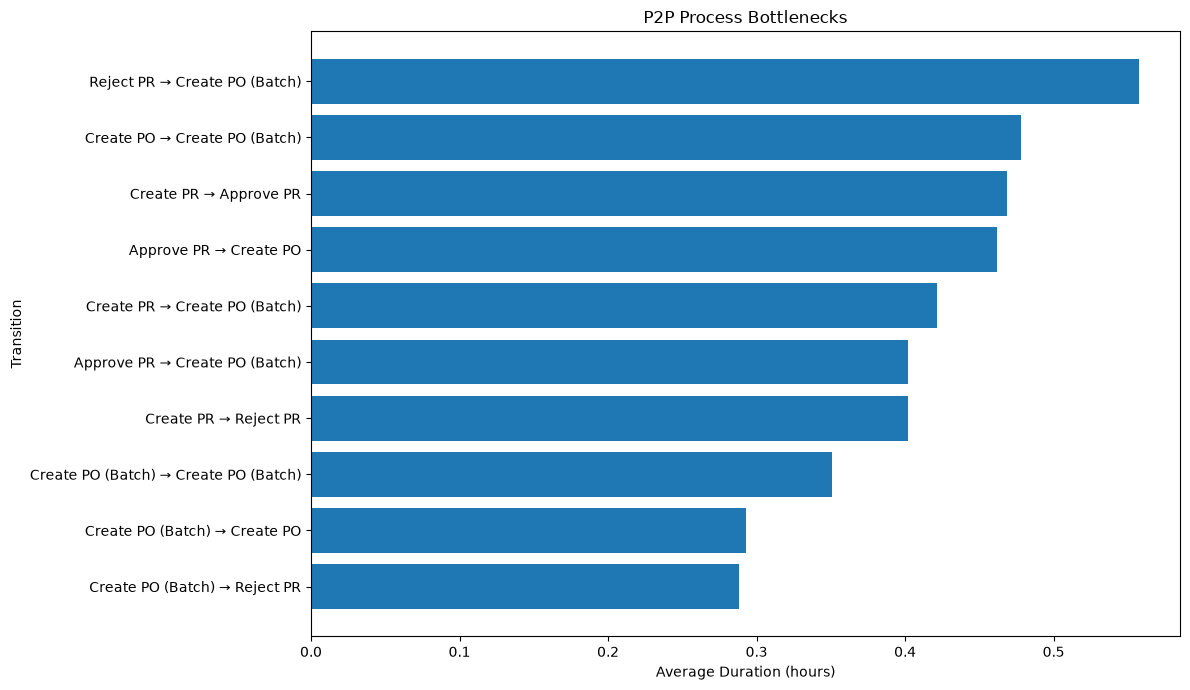

In [52]:
plt.figure(figsize=(12, 7))

plot_df = transition_summary.head(10).copy()

plot_df["transition"] = (
    plot_df["from_activity"]
    + " → "
    + plot_df["to_activity"]
)

plot_df = plot_df.sort_values("average_hours")

plt.barh(
    plot_df["transition"],
    plot_df["average_hours"]
)

plt.xlabel("Average Duration (hours)")
plt.ylabel("Transition")
plt.title("P2P Process Bottlenecks")

plt.tight_layout()
plt.show()

In [53]:
variant_summary = (
    pr_timeline
    .groupby("process_path")
    .agg(
        frequency=("ocel:oid", "count")
    )
    .reset_index()
)

variant_summary["percentage"] = (
    variant_summary["frequency"]
    / variant_summary["frequency"].sum()
    * 100
)

In [54]:
variant_duration = (
    pr_duration
    .merge(
        pr_timeline[
            ["ocel:oid", "process_path"]
        ],
        on="ocel:oid",
        how="left"
    )
    .groupby("process_path")
    .agg(
        frequency=("ocel:oid", "count"),
        average_duration_hours=("duration_hours", "mean"),
        median_duration_hours=("duration_hours", "median"),
        p90_duration_hours=(
            "duration_hours",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
    .sort_values(
        "average_duration_hours",
        ascending=False
    )
)

variant_duration.head(20)

,process_path,frequency,average_duration_hours,median_duration_hours,p90_duration_hours
59,Create PR → Create PO (Batch) → Approve PR → C...,1,2.500000,2.500000,2.500000
3,Create PO (Batch) → Create PO (Batch) → Create...,1,2.149722,2.149722,2.149722
50,Create PR → Approve PR → Create PO → Create PO...,2,2.083472,2.083472,2.177139
39,Create PR → Approve PR → Create PO (Batch) → C...,1,2.083056,2.083056,2.083056
45,Create PR → Approve PR → Create PO (Batch) → C...,1,2.049444,2.049444,2.049444
73,Create PR → Create PO (Batch) → Create PO (Bat...,1,2.000833,2.000833,2.000833
49,Create PR → Approve PR → Create PO → Create PO...,2,1.984167,1.984167,2.037278
61,Create PR → Create PO (Batch) → Approve PR → C...,1,1.982778,1.982778,1.982778
80,Create PR → Create PO (Batch) → Reject PR → Cr...,1,1.933611,1.933611,1.933611
48,Create PR → Approve PR → Create PO → Create PO...,14,1.915357,1.816806,2.554556


In [55]:
from pathlib import Path
import sys

# Find the project root automatically
current_path = Path.cwd()

for path in [current_path, *current_path.parents]:
    if (path / "src").is_dir():
        PROJECT_ROOT = path
        break
else:
    raise FileNotFoundError(
        "Could not find project root containing 'src' folder."
    )

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /Users/debarghamishra/Downloads/Agentic_process_Intelligence


In [56]:
from src.data.data_loader import load_all

events, relations, objects = load_all()

print("Events:", events.shape)
print("Relations:", relations.shape)
print("Objects:", objects.shape)


Looking for database at:
/Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/lrms_02_p2p.sqlite
Events: (8300, 6)
Relations: (16827, 6)
Objects: (4493, 13)


In [57]:
events["ocel:activity"].value_counts()

ocel:activity
Create PR                           1000
Approve PR                           900
Approve PO                           900
Send PO to Supplier                  900
Receive Goods                        900
Receive Invoice                      900
Make Payment                         900
Three-way Match - Successful         823
Create PO (Batch)                    457
Create PO                            443
Reject PR                            100
Three-way Match - Mismatch Found      77
Name: count, dtype: int64

In [58]:
objects["ocel:type"].value_counts()

ocel:type
Purchase Requisition    1000
Purchase Order           870
Goods Receipt            858
Invoice                  858
Payment                  857
Supplier                  50
Name: count, dtype: int64

In [59]:
relations["ocel:type"].value_counts()

ocel:type
Purchase Order          5400
Purchase Requisition    4227
Invoice                 2700
Supplier                1800
Goods Receipt           1800
Payment                  900
Name: count, dtype: int64